In [50]:
#imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
from matplotlib.lines import Line2D
import os

### I. Cleaning near road reference site

In [51]:
file_path = "raw input data/raw near road reference data/near road no2 23 24.csv"
df = pd.read_csv(file_path)

df["datetime_est"] = pd.to_datetime(df["datetime_est"], format="mixed")
df["datetime_utc"] = df["datetime_est"].dt.tz_localize("Etc/GMT+5")
df["datetime_utc"] = df["datetime_utc"].dt.tz_convert("UTC")
df["datetime_utc"] = df["datetime_utc"].dt.tz_localize(None)

df = df.drop(columns=["datetime_est"])
df = df[["datetime_utc", "no2"]]

print(df.head())
print(df.dtypes)

         datetime_utc   no2
0 2023-01-01 05:00:00  11.2
1 2023-01-01 06:00:00   8.6
2 2023-01-01 07:00:00   6.9
3 2023-01-01 08:00:00   4.8
4 2023-01-01 09:00:00   7.1
datetime_utc    datetime64[ns]
no2                    float64
dtype: object


In [52]:
df_clean = df.copy()
n_negative = (df_clean["no2"] < 0).sum()

df_clean.loc[df_clean["no2"] < 0, "no2"] = np.nan
df_clean = df_clean.set_index("datetime_utc")

full_index = pd.date_range(df_clean.index.min(), df_clean.index.max(), freq="h")
df_clean = df_clean.reindex(full_index)


df_clean.index.name = "datetime_utc"
n_missing_before = df_clean["no2"].isna().sum()
is_missing = df_clean["no2"].isna()


group_id = (is_missing != is_missing.shift()).cumsum()
gap_length = is_missing.groupby(group_id).transform("sum")

interpolated = df_clean["no2"].interpolate(method="linear", limit_area="inside")

long_gap = is_missing & (gap_length > 6)

df_clean["no2"] = interpolated.mask(long_gap)

df_clean = df_clean.reset_index()
n_missing_after = df_clean["no2"].isna().sum()
df_clean["no2"] = df_clean["no2"].round(1)

print("Negative values removed:", n_negative)
print("Missing values before interpolation:", n_missing_before)
print("Missing values after interpolation:", n_missing_after)
print("Values filled in:", n_missing_before - n_missing_after)

print(df_clean.head())
df_clean.to_csv("cleaned data/cleaned near road reference data/nr cleaned no2 23 24.csv", index=False)


Negative values removed: 18
Missing values before interpolation: 3291
Missing values after interpolation: 2599
Values filled in: 692
         datetime_utc   no2
0 2023-01-01 05:00:00  11.2
1 2023-01-01 06:00:00   8.6
2 2023-01-01 07:00:00   6.9
3 2023-01-01 08:00:00   4.8
4 2023-01-01 09:00:00   7.1


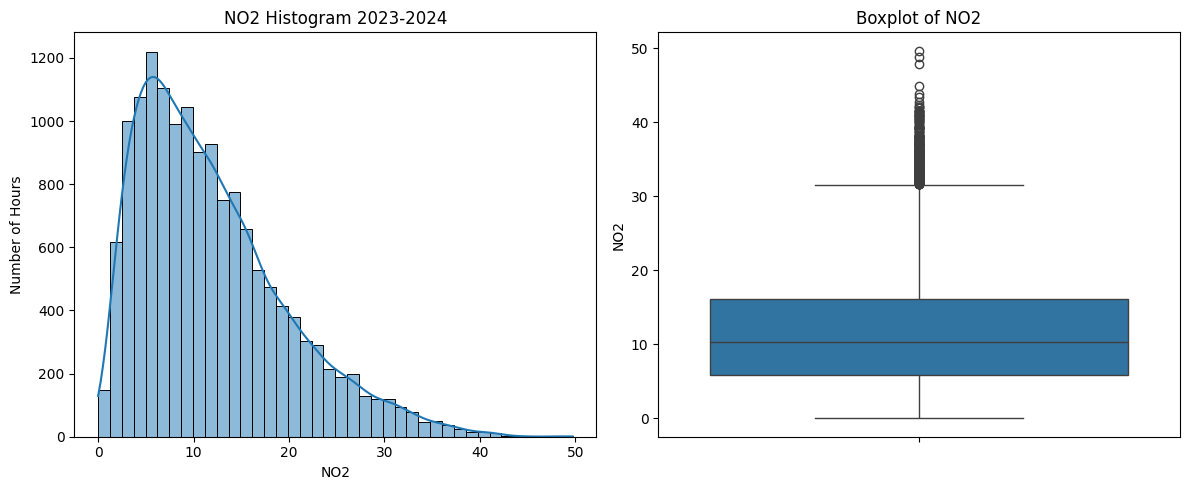

count    14945.00
mean        11.93
std          7.78
min          0.00
25%          5.90
50%         10.30
75%         16.20
max         49.70
Name: no2, dtype: float64


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(df_clean["no2"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("NO2 Histogram 2023-2024")
axes[0].set_xlabel("NO2")
axes[0].set_ylabel("Number of Hours")

sns.boxplot(y=df_clean["no2"].dropna(), ax=axes[1])
axes[1].set_title("Boxplot of NO2")
axes[1].set_ylabel("NO2")

plt.tight_layout()
plt.show()

print(df_clean["no2"].describe().round(2))

### II. Clean raw BEACO2N data

In [54]:
raw_folder = "raw input data/raw beacon data"
out_both = "cleaned data/cleaned beacon data 23 24"

columns_to_keep = [
    "datetime",
    "co2_corrected_avg_t_drift_applied",
    "co_wrk_aux",
    "no2_wrk_aux",
    "no_wrk_aux",
    "o3_wrk_aux",
    "rh",
    "temp"
    ]

rename_map = {
    "datetime": "datetime_utc",
    "co2_corrected_avg_t_drift_applied": "co2"
}

round_to_1dp = ["co2", "rh", "temp"]
round_to_6dp = ["co_wrk_aux", "no2_wrk_aux", "no_wrk_aux", "o3_wrk_aux"]

dt_format = "%Y-%m-%d %H:%M:%S"

for i in range(1, 26):
    xx = f"{i:02d}"
    in_path = f"{raw_folder}/Sensor{xx}_raw.csv"
    sensor = pd.read_csv(in_path, usecols=columns_to_keep, parse_dates=["datetime"])

    sensor = sensor.rename(columns=rename_map)
    sensor = sensor[["datetime_utc"] + round_to_1dp[:1] + round_to_6dp + round_to_1dp[1:]]
    sensor[round_to_1dp] = sensor[round_to_1dp].round(1)
    sensor[round_to_6dp] = sensor[round_to_6dp].round(6)

    sensor.to_csv(
        f"{out_both}/Sensor{xx}_cleaned2324.csv",
        index=False,
        date_format=dt_format,
    )

    years = sensor["datetime_utc"].dt.year

    print(
        f"Sensor{xx}: {len(sensor)} total rows, "
        f"{(years == 2023).sum()} in 2023, {(years == 2024).sum()} in 2024"
    )


Sensor01: 17156 total rows, 8620 in 2023, 8536 in 2024
Sensor02: 17444 total rows, 8663 in 2023, 8781 in 2024
Sensor03: 17332 total rows, 8560 in 2023, 8772 in 2024
Sensor04: 16178 total rows, 8367 in 2023, 7811 in 2024
Sensor05: 17455 total rows, 8745 in 2023, 8710 in 2024
Sensor06: 15446 total rows, 7029 in 2023, 8417 in 2024
Sensor07: 16886 total rows, 8393 in 2023, 8493 in 2024
Sensor08: 17223 total rows, 8741 in 2023, 8482 in 2024
Sensor09: 17368 total rows, 8743 in 2023, 8625 in 2024
Sensor10: 14614 total rows, 8505 in 2023, 6109 in 2024
Sensor11: 17248 total rows, 8742 in 2023, 8506 in 2024
Sensor12: 15884 total rows, 8746 in 2023, 7138 in 2024
Sensor13: 16198 total rows, 8210 in 2023, 7988 in 2024
Sensor14: 14621 total rows, 5948 in 2023, 8673 in 2024
Sensor15: 16413 total rows, 7736 in 2023, 8677 in 2024
Sensor16: 17466 total rows, 8714 in 2023, 8752 in 2024
Sensor17: 15346 total rows, 7164 in 2023, 8182 in 2024
Sensor18: 16512 total rows, 7741 in 2023, 8771 in 2024
Sensor19: 

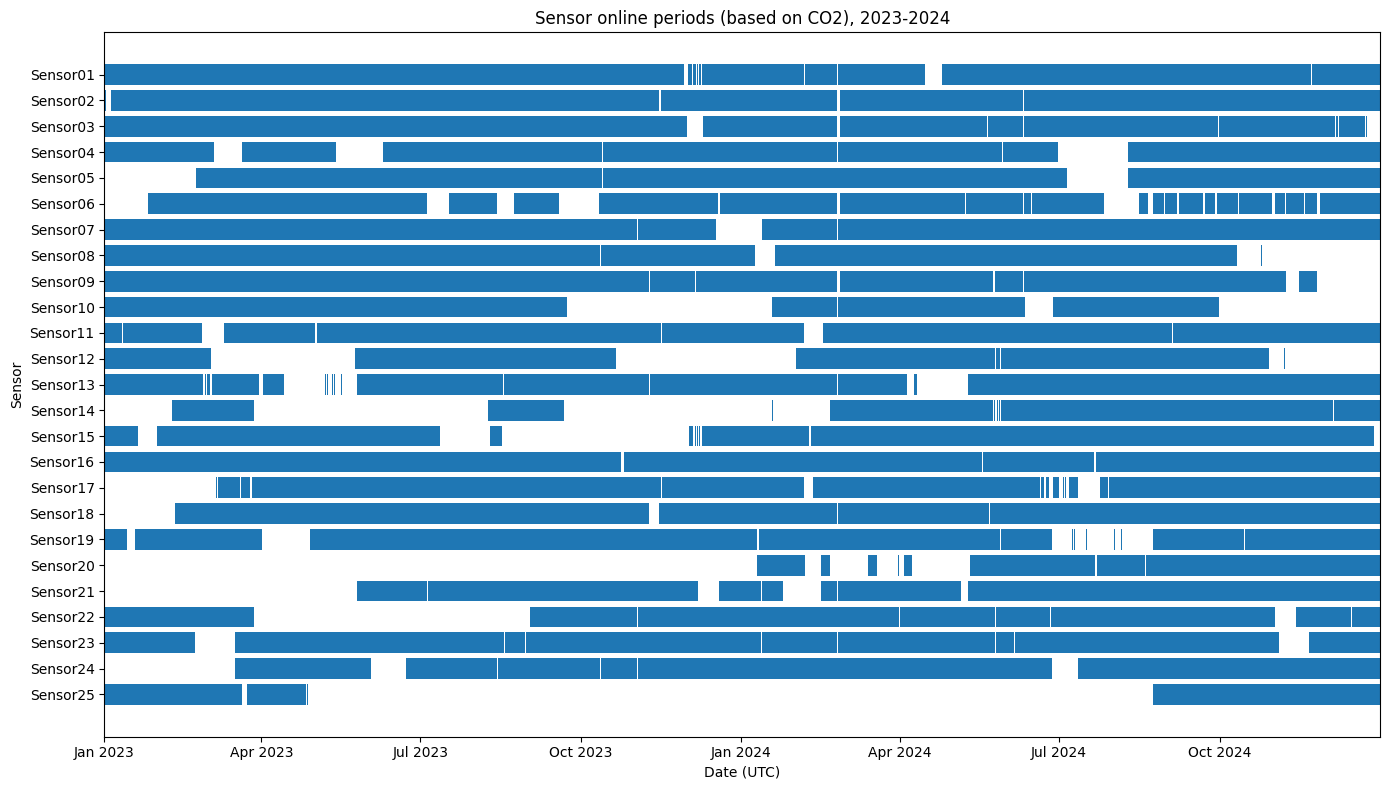

Median sites online: 20.0
25th percentile: 19.0
75th percentile: 22.0
10th percentile 18.0

Percent of hours online, by sensor:
Sensor01    97.7
Sensor02    99.1
Sensor03    97.1
Sensor04    88.5
Sensor05    87.9
Sensor06    85.1
Sensor07    96.2
Sensor08    87.3
Sensor09    93.4
Sensor10    69.1
Sensor11    96.3
Sensor12    65.8
Sensor13    89.2
Sensor14    55.3
Sensor15    79.0
Sensor16    99.4
Sensor17    87.2
Sensor18    93.6
Sensor19    87.7
Sensor20    37.8
Sensor21    74.9
Sensor22    76.3
Sensor23    94.1
Sensor24    84.6
Sensor25    33.4
dtype: float64


In [55]:
folder = "cleaned data/cleaned beacon data 23 24"

full_index = pd.date_range("2023-01-01 00:00:00", "2024-12-31 23:00:00", freq="h")

co2_dict = {}
for i in range(1, 26):
    xx = f"{i:02d}"
    path = f"{folder}/Sensor{xx}_cleaned2324.csv"

    s = pd.read_csv(path, usecols=["datetime_utc", "co2"], parse_dates=["datetime_utc"])

    s = s.set_index("datetime_utc")

    co2_dict[f"Sensor{xx}"] = s["co2"].reindex(full_index)

co2_wide = pd.DataFrame(co2_dict)
online = co2_wide.notna()

fig, ax = plt.subplots(figsize=(14, 8))

for row, name in enumerate(online.columns):
    status = online[name]
    run_id = (status != status.shift()).cumsum()

    times = pd.Series(status.index, index=status.index)[status]

    grp = run_id[status]

    starts = times.groupby(grp).min()

    lengths = times.groupby(grp).size()

    bars = [(mdates.date2num(s), n / 24) for s, n in zip(starts, lengths)]

    ax.broken_barh(bars, (row - 0.4, 0.8))

ax.set_yticks(range(len(online.columns)))
ax.set_yticklabels(online.columns)

ax.invert_yaxis()

ax.xaxis_date()
ax.set_xlim(full_index[0], full_index[-1])

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.set_title("Sensor online periods (based on CO2), 2023-2024")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Sensor")

plt.tight_layout()
plt.show()

n_online = online.sum(axis=1)

print("Median sites online:", round(n_online.median(), 2))

print("25th percentile:", n_online.quantile(0.25))

print("75th percentile:", n_online.quantile(0.75))

print("10th percentile", n_online.quantile(0.10))

print("\nPercent of hours online, by sensor:")
print((online.mean() * 100).round(1))

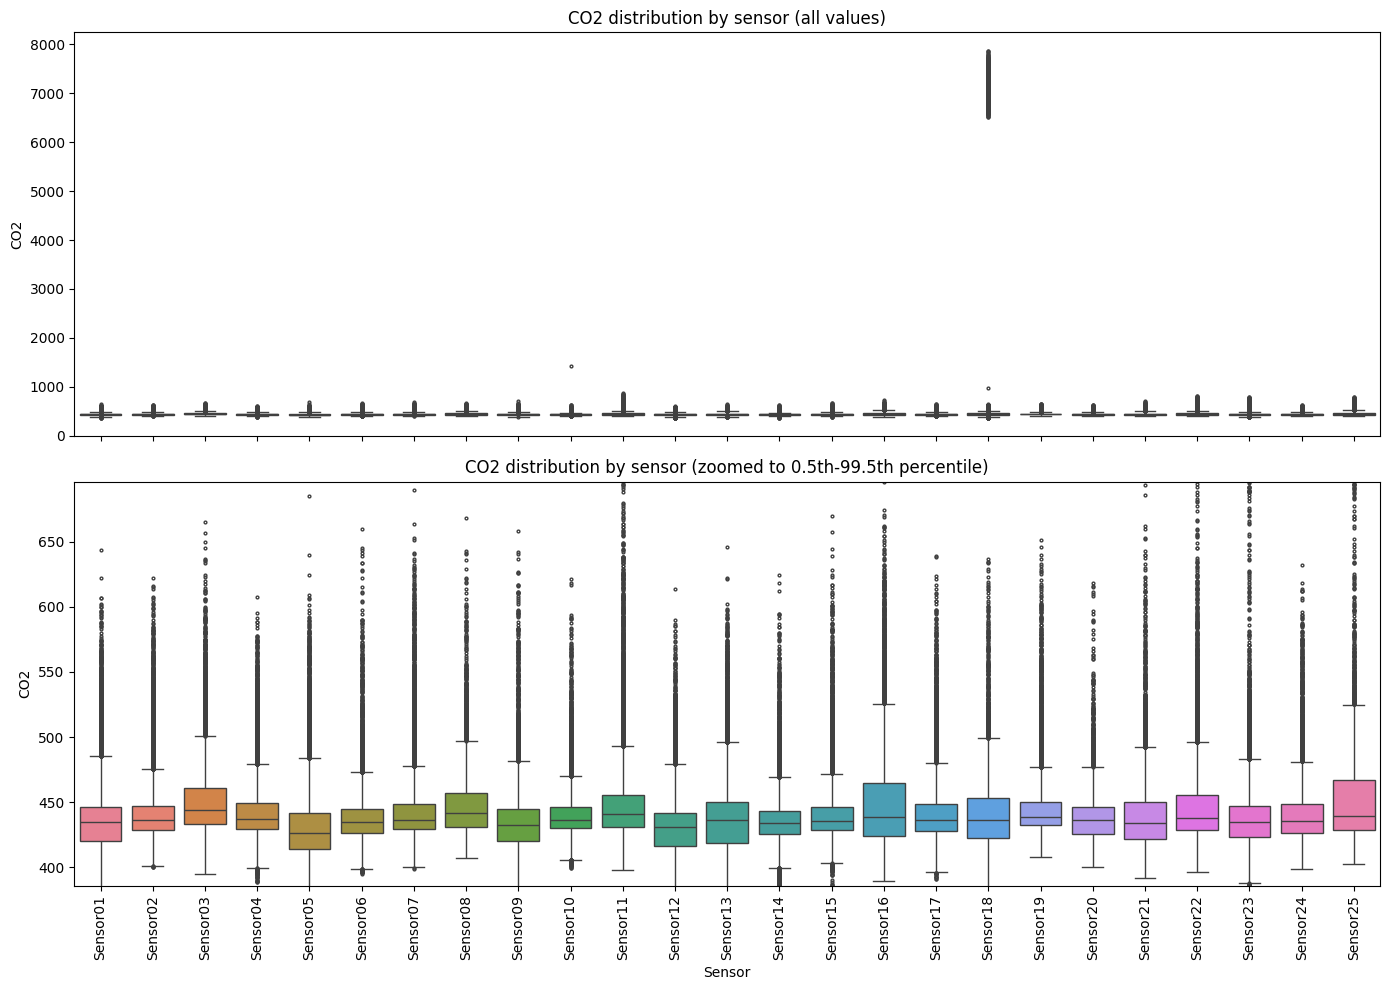


Max CO2 by sensor:
Sensor01     643.7
Sensor02     622.0
Sensor03     664.9
Sensor04     607.3
Sensor05     684.9
Sensor06     660.1
Sensor07     689.5
Sensor08     668.5
Sensor09     698.4
Sensor10    1419.8
Sensor11     873.6
Sensor12     613.6
Sensor13     646.0
Sensor14     624.7
Sensor15     670.2
Sensor16     722.2
Sensor17     639.3
Sensor18    7872.8
Sensor19     651.2
Sensor20     618.4
Sensor21     708.9
Sensor22     815.0
Sensor23     793.8
Sensor24     632.3
Sensor25     792.3

Min CO2 by sensor:
Sensor01    367.1
Sensor02    400.1
Sensor03    395.1
Sensor04    388.9
Sensor05    377.7
Sensor06    394.9
Sensor07    398.4
Sensor08    407.2
Sensor09    381.6
Sensor10    399.4
Sensor11    398.2
Sensor12    358.1
Sensor13    369.9
Sensor14    367.6
Sensor15    386.4
Sensor16    389.4
Sensor17    391.0
Sensor18    363.9
Sensor19    407.5
Sensor20    400.4
Sensor21    391.8
Sensor22    396.1
Sensor23    384.2
Sensor24    398.7
Sensor25    402.7


In [56]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

sns.boxplot(data=co2_wide, ax=axes[0], fliersize=2)
axes[0].set_title("CO2 distribution by sensor (all values)")
axes[0].set_ylabel("CO2")

low = co2_wide.stack().quantile(0.005)
high = co2_wide.stack().quantile(0.995)


sns.boxplot(data=co2_wide, ax=axes[1], fliersize=2)
axes[1].set_ylim(low, high)
axes[1].set_title("CO2 distribution by sensor (zoomed to 0.5th-99.5th percentile)")
axes[1].set_ylabel("CO2")
axes[1].set_xlabel("Sensor")

plt.setp(axes[1].get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

print("\nMax CO2 by sensor:")
print(co2_wide.max().round(1).to_string())
print("\nMin CO2 by sensor:")
print(co2_wide.min().round(1).to_string())

### III a. Create CO2 dataset and identify no split low RSD time periods

In [57]:
#based on above data, we use a CO2 cutoff of 850. Remove that data and overwrite
#we will recalculate the 10th percentile of when sites are online based on this


#the loop and dictionary structure here are left over from when I briefly
#considered using seprate 2023 and 2024 datasets as tests.
co2_cutoff = 850
folders = {
    "cleaned data/cleaned beacon data 23 24": "cleaned2324",
}

dt_format = "%Y-%m-%d %H:%M:%S"

for folder_name, suffix in folders.items():
    total_removed = 0

    for i in range(1, 26):

        xx = f"{i:02d}"
        path = f"{folder_name}/Sensor{xx}_{suffix}.csv"

        sensor = pd.read_csv(path, parse_dates=["datetime_utc"])

        too_high = sensor["co2"] > co2_cutoff

        total_removed += too_high.sum()

        sensor.loc[too_high, "co2"] = np.nan


        sensor.to_csv(path, index=False, date_format=dt_format)

    print(f"{folder_name}: {total_removed} CO2 values set to NaN")

cleaned data/cleaned beacon data 23 24: 1440 CO2 values set to NaN


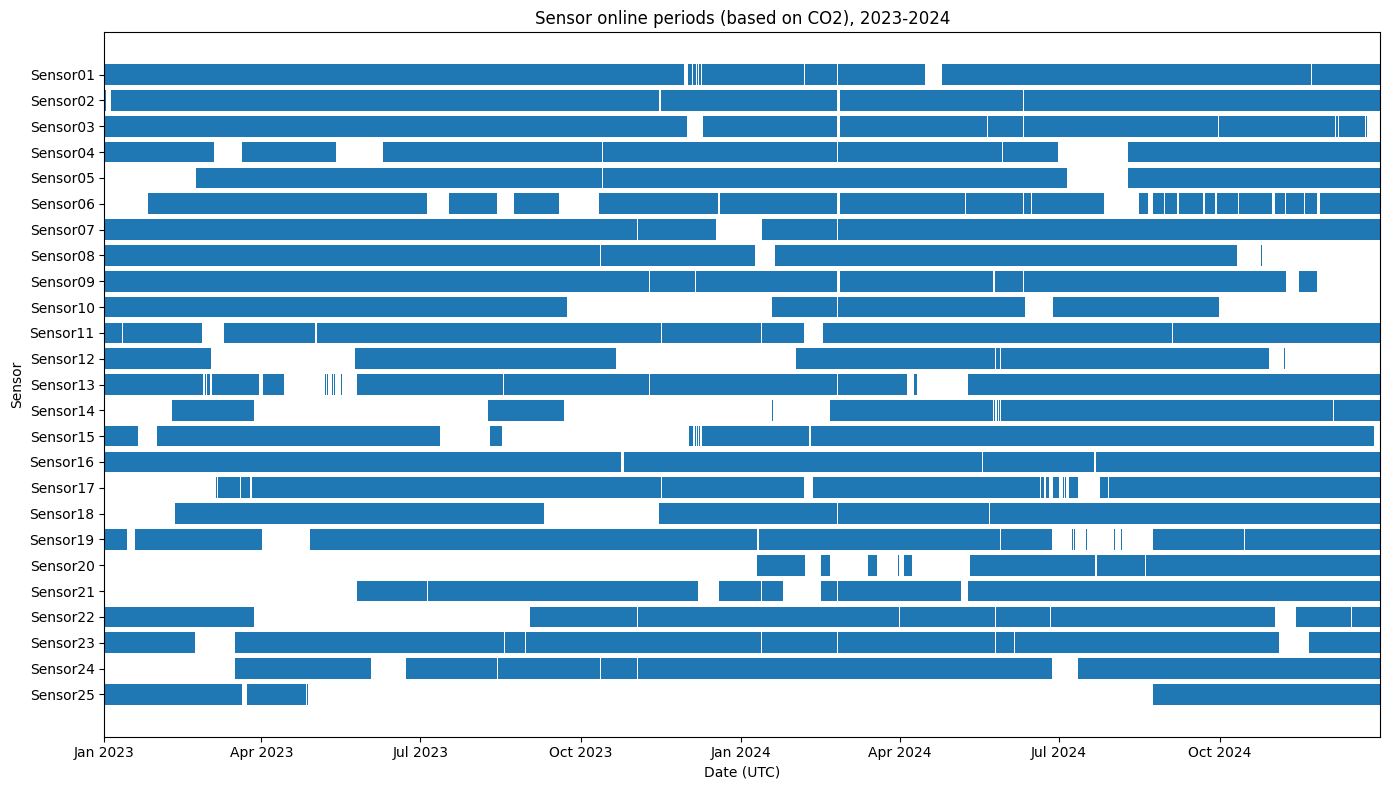

Median sites online: 20.0
25th percentile: 19.0
75th percentile: 22.0
10th percentile 18.0

Percent of hours online, by sensor:
Sensor01    97.7
Sensor02    99.1
Sensor03    97.1
Sensor04    88.5
Sensor05    87.9
Sensor06    85.1
Sensor07    96.2
Sensor08    87.3
Sensor09    93.4
Sensor10    69.1
Sensor11    96.3
Sensor12    65.8
Sensor13    89.2
Sensor14    55.3
Sensor15    79.0
Sensor16    99.4
Sensor17    87.2
Sensor18    85.4
Sensor19    87.7
Sensor20    37.8
Sensor21    74.9
Sensor22    76.3
Sensor23    94.1
Sensor24    84.6
Sensor25    33.4
dtype: float64


In [58]:
#test to see how online numbers change after filtering CO2 values

folder = "cleaned data/cleaned beacon data 23 24"

full_index = pd.date_range("2023-01-01 00:00:00", "2024-12-31 23:00:00", freq="h")

co2_dict = {}
for i in range(1, 26):
    xx = f"{i:02d}"
    path = f"{folder}/Sensor{xx}_cleaned2324.csv"

    s = pd.read_csv(path, usecols=["datetime_utc", "co2"], parse_dates=["datetime_utc"])

    s = s.set_index("datetime_utc")

    co2_dict[f"Sensor{xx}"] = s["co2"].reindex(full_index)

co2_wide = pd.DataFrame(co2_dict)
online = co2_wide.notna()

fig, ax = plt.subplots(figsize=(14, 8))

for row, name in enumerate(online.columns):
    status = online[name]
    run_id = (status != status.shift()).cumsum()

    times = pd.Series(status.index, index=status.index)[status]

    grp = run_id[status]

    starts = times.groupby(grp).min()

    lengths = times.groupby(grp).size()

    bars = [(mdates.date2num(s), n / 24) for s, n in zip(starts, lengths)]

    ax.broken_barh(bars, (row - 0.4, 0.8))

ax.set_yticks(range(len(online.columns)))
ax.set_yticklabels(online.columns)

ax.invert_yaxis()

ax.xaxis_date()
ax.set_xlim(full_index[0], full_index[-1])

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.set_title("Sensor online periods (based on CO2), 2023-2024")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Sensor")

plt.tight_layout()
plt.show()

n_online = online.sum(axis=1)

print("Median sites online:", round(n_online.median(), 2))

print("25th percentile:", n_online.quantile(0.25))

print("75th percentile:", n_online.quantile(0.75))

print("10th percentile", n_online.quantile(0.10))

print("\nPercent of hours online, by sensor:")
print((online.mean() * 100).round(1))

In [59]:
co2_out = co2_wide.copy()
co2_out.index.name = "datetime_utc"

co2_out = co2_out.reset_index()
co2_out.insert(1, "datetime_est", co2_out["datetime_utc"] - pd.Timedelta(hours=5))
co2_out.insert(2, "datetime_edt", co2_out["datetime_utc"] - pd.Timedelta(hours=4))

out_path = "cleaned data/cleaned co2/cleaned_co2_bysite.csv"
co2_out.to_csv(out_path, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("Shape:", co2_out.shape)
print(co2_out.head())

Shape: (17544, 28)
         datetime_utc        datetime_est        datetime_edt  Sensor01  \
0 2023-01-01 00:00:00 2022-12-31 19:00:00 2022-12-31 20:00:00     436.6   
1 2023-01-01 01:00:00 2022-12-31 20:00:00 2022-12-31 21:00:00     435.8   
2 2023-01-01 02:00:00 2022-12-31 21:00:00 2022-12-31 22:00:00     435.4   
3 2023-01-01 03:00:00 2022-12-31 22:00:00 2022-12-31 23:00:00     434.8   
4 2023-01-01 04:00:00 2022-12-31 23:00:00 2023-01-01 00:00:00     437.2   

   Sensor02  Sensor03  Sensor04  Sensor05  Sensor06  Sensor07  ...  Sensor16  \
0     483.1     470.7     474.7       NaN       NaN     456.7  ...     457.6   
1     469.2     459.7     459.3       NaN       NaN     462.2  ...     463.2   
2     458.1     443.4     463.5       NaN       NaN     453.6  ...     455.7   
3     450.4     437.8     456.6       NaN       NaN     448.9  ...     441.1   
4     449.3     438.1     449.3       NaN       NaN     457.0  ...     460.3   

   Sensor17  Sensor18  Sensor19  Sensor20  Sensor

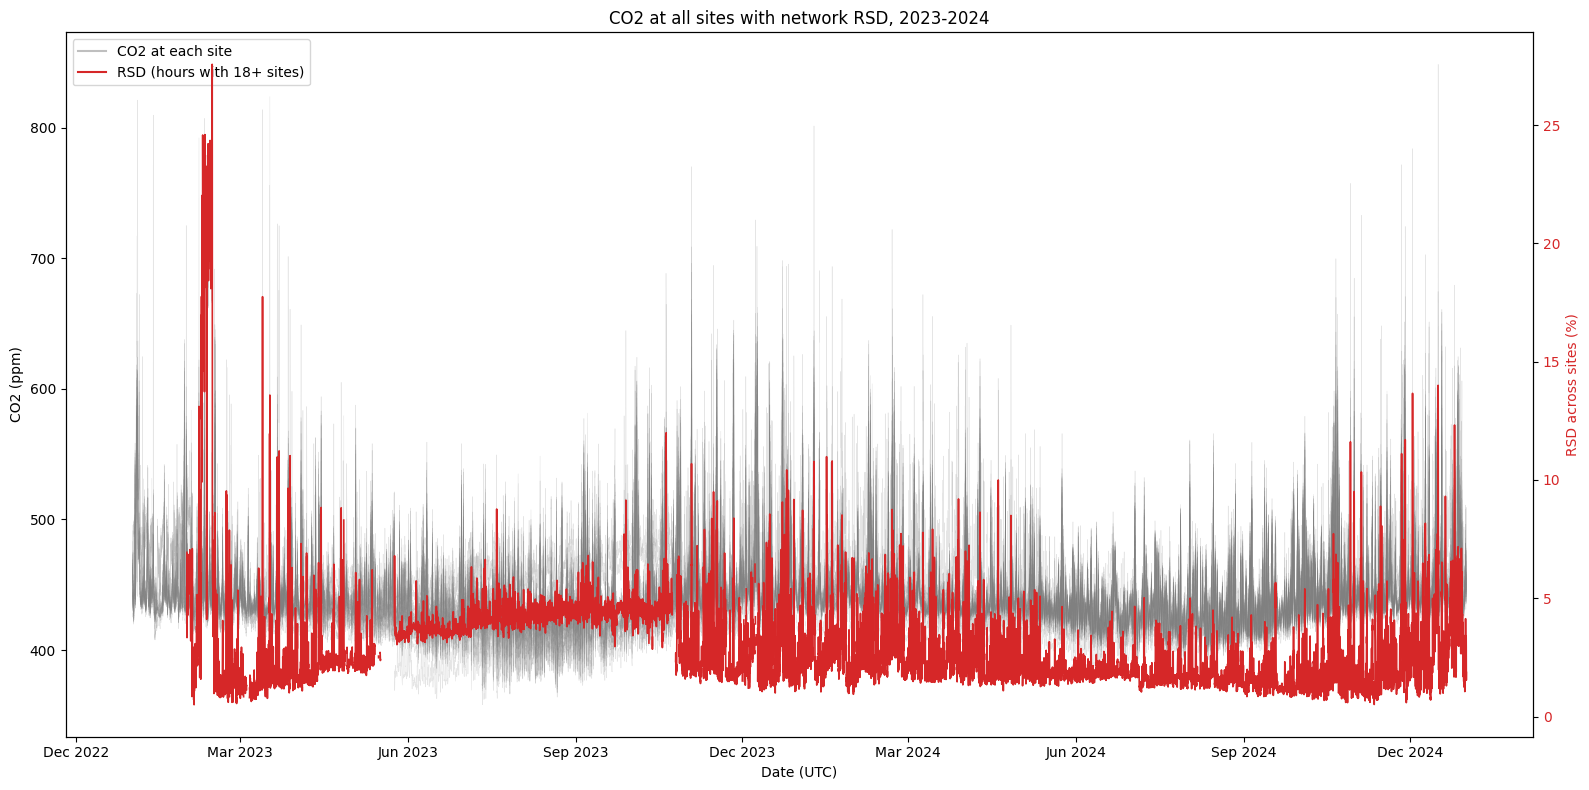

count    16246.00
mean         2.98
std          2.21
min          0.50
25%          1.69
50%          2.37
75%          3.92
max         27.57


In [60]:
min_sites = 18
n_online = co2_wide.notna().sum(axis=1)
sd_across = co2_wide.std(axis=1)
mean_across = co2_wide.mean(axis=1)
rsd = sd_across / mean_across * 100
rsd = rsd.where(n_online >= min_sites)

fig, ax1 = plt.subplots(figsize=(16,8))
for name in co2_wide.columns:
    ax1.plot(co2_wide.index, co2_wide[name], color="gray", linewidth=0.4, alpha=0.2)

ax1.set_ylabel("CO2 (ppm)")
ax1.set_xlabel("Date (UTC)")

ax2 = ax1.twinx()
ax2.plot(rsd.index, rsd, color="tab:red", linewidth=1.2)
ax2.set_ylabel("RSD across sites (%)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
ax2.grid(False)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

legend_items = [
    Line2D([0], [0], color="gray", alpha=0.5, label="CO2 at each site"),
    Line2D([0], [0], color="tab:red", label=f"RSD (hours with {min_sites}+ sites)"),
]

ax1.legend(handles=legend_items, loc="upper left")

ax1.set_title("CO2 at all sites with network RSD, 2023-2024")

plt.tight_layout()
plt.show()

print(rsd.describe().round(2).to_string())

In [62]:
valid_rsd = rsd.dropna()

rsd_cutoff = valid_rsd.quantile(0.10)

low_rsd = valid_rsd[valid_rsd <= rsd_cutoff]
low_rsd_df = low_rsd.to_frame(name="rsd_percent")

low_rsd_df.index.name = "datetime_utc"

low_rsd_df = low_rsd_df.reset_index()

low_rsd_df["rsd_percent"] = low_rsd_df["rsd_percent"].round(3)

out_path = "low RSD time periods/no split low RSD time periods/low_rsd_hours.csv"
low_rsd_df.to_csv(out_path, index=False, date_format="%Y-%m-%d %H:%M:%S")
print(f"RSD cutoff (10th percentile of valid hours): {rsd_cutoff:.3f}%")

print("Valid RSD hours:", len(valid_rsd))
print("Low-RSD hours saved:", len(low_rsd_df))

print(low_rsd_df.head())

RSD cutoff (10th percentile of valid hours): 1.332%
Valid RSD hours: 16246
Low-RSD hours saved: 1625
         datetime_utc  rsd_percent
0 2023-02-02 16:00:00        0.848
1 2023-02-02 17:00:00        1.071
2 2023-02-02 18:00:00        1.036
3 2023-02-03 13:00:00        1.296
4 2023-02-03 14:00:00        0.845


### III b. Creating no split training and testing datasets with Beacon data

In [63]:
beacon_folder = "cleaned data/cleaned beacon data 23 24"
ref_path = "cleaned data/cleaned near road reference data/nr cleaned no2 23 24.csv"
low_rsd_path = "low RSD time periods/no split low RSD time periods/low_rsd_hours.csv"
out_folder = "training and testing data/no split training and testing data"

dt_format = "%Y-%m-%d %H:%M:%S"

keep_cols = ["datetime_utc", "co_wrk_aux", "no2_wrk_aux",
             "no_wrk_aux", "o3_wrk_aux", "rh", "temp"]

ref = pd.read_csv(ref_path, parse_dates=["datetime_utc"])

low_times = pd.read_csv(low_rsd_path, parse_dates=["datetime_utc"])["datetime_utc"]

for i in range(1, 26):
    xx = f"{i:02d}"

    in_path = f"{beacon_folder}/Sensor{xx}_cleaned2324.csv"

    sensor = pd.read_csv(in_path, usecols=keep_cols, parse_dates=["datetime_utc"])
    sensor = sensor[sensor["datetime_utc"].dt.year.isin([2023, 2024])]
    sensor = sensor[keep_cols]

    testing = sensor.merge(ref, on="datetime_utc", how="left")

    testing.to_csv(f"{out_folder}/Sensor{xx}_testing.csv",
                   index=False, date_format=dt_format)


    training = testing[testing["datetime_utc"].isin(low_times)].copy()
    training = training.dropna().copy()

    training.to_csv(f"{out_folder}/Sensor{xx}_training.csv",
                    index=False, date_format=dt_format)

    print(f"Sensor{xx}: testing {len(testing)} rows "
          f"({testing['no2'].notna().sum()} with reference NO2), "
          f"training {len(training)} rows "
          f"({training['no2'].notna().sum()} with reference NO2)")

Sensor01: testing 17156 rows (14560 with reference NO2), training 1438 rows (1438 with reference NO2)
Sensor02: testing 17444 rows (14842 with reference NO2), training 1440 rows (1440 with reference NO2)
Sensor03: testing 17332 rows (14729 with reference NO2), training 1424 rows (1424 with reference NO2)
Sensor04: testing 16178 rows (13888 with reference NO2), training 1245 rows (1245 with reference NO2)
Sensor05: testing 17455 rows (14871 with reference NO2), training 1371 rows (1371 with reference NO2)
Sensor06: testing 15446 rows (13008 with reference NO2), training 1322 rows (1322 with reference NO2)
Sensor07: testing 16886 rows (14283 with reference NO2), training 1421 rows (1421 with reference NO2)
Sensor08: testing 17223 rows (14620 with reference NO2), training 1424 rows (1424 with reference NO2)
Sensor09: testing 17368 rows (14766 with reference NO2), training 1416 rows (1416 with reference NO2)
Sensor10: testing 14614 rows (12036 with reference NO2), training 876 rows (876 wi

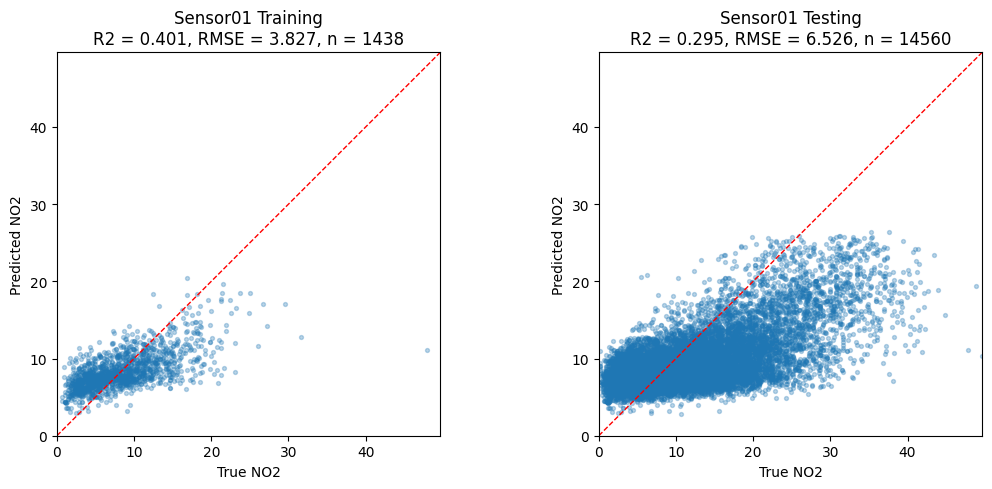

Training Sensor01 complete


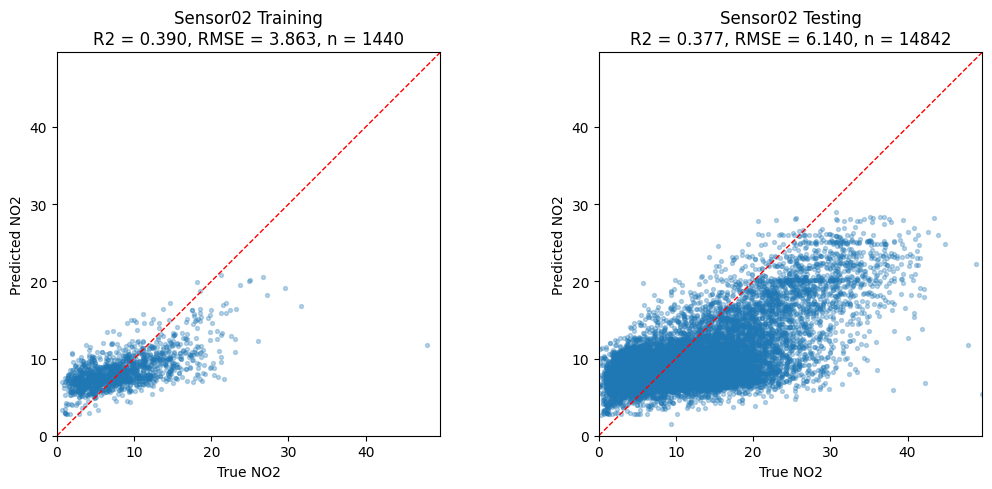

Training Sensor02 complete


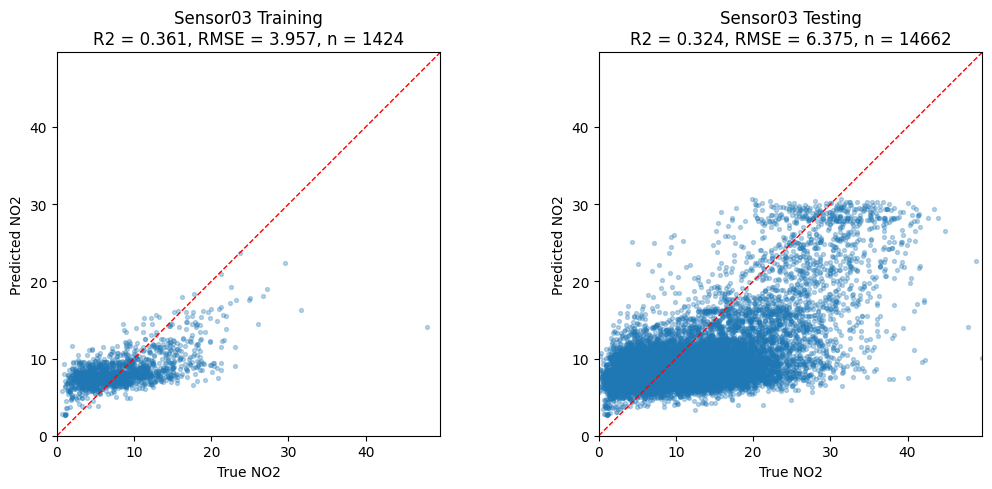

Training Sensor03 complete


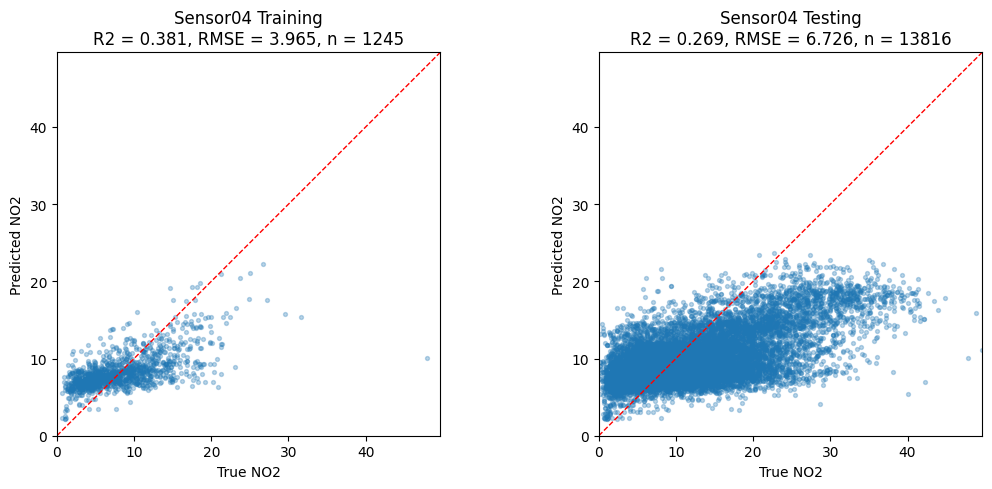

Training Sensor04 complete


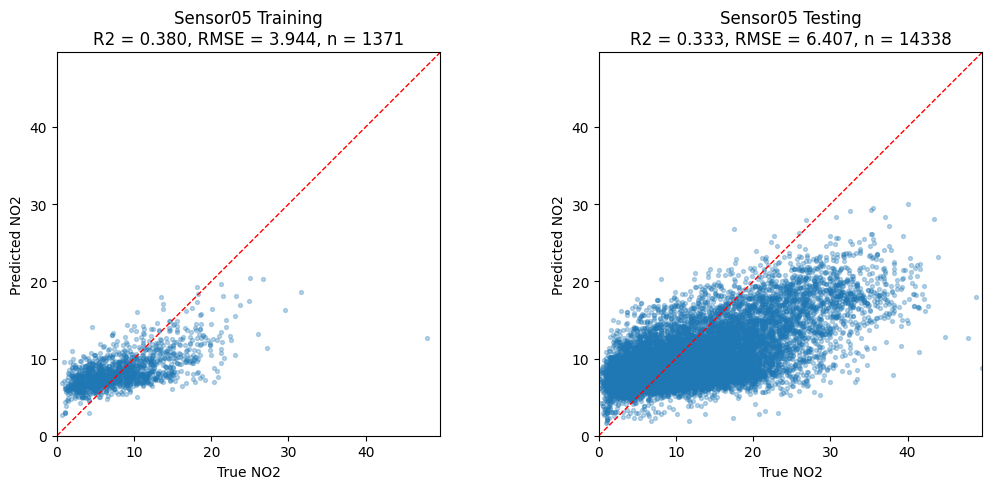

Training Sensor05 complete


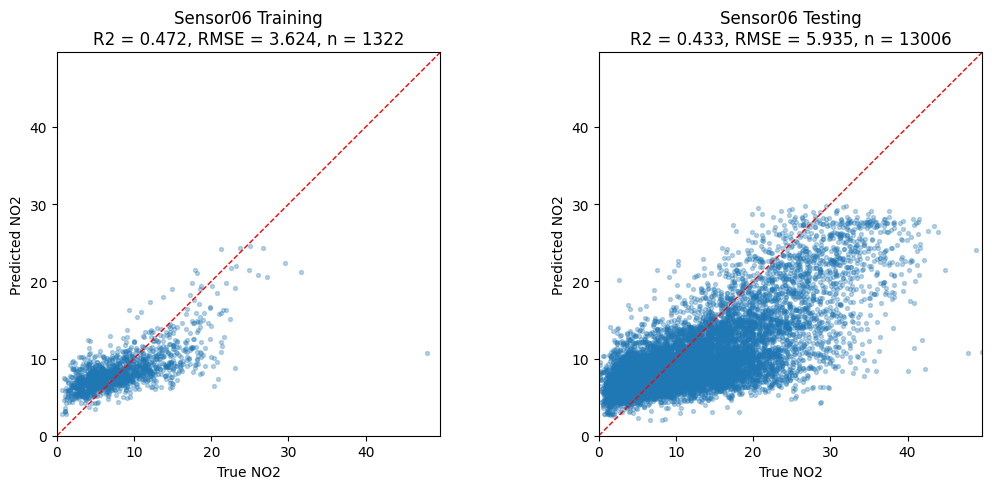

Training Sensor06 complete


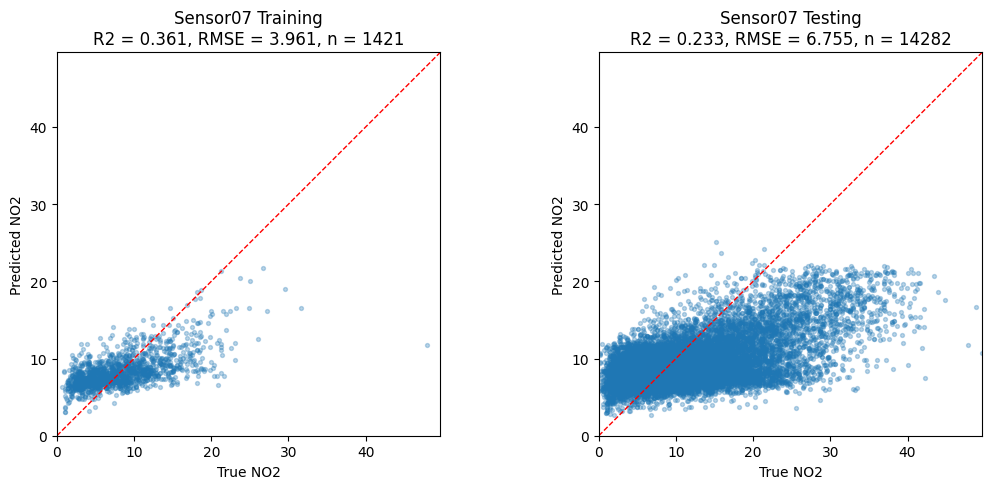

Training Sensor07 complete


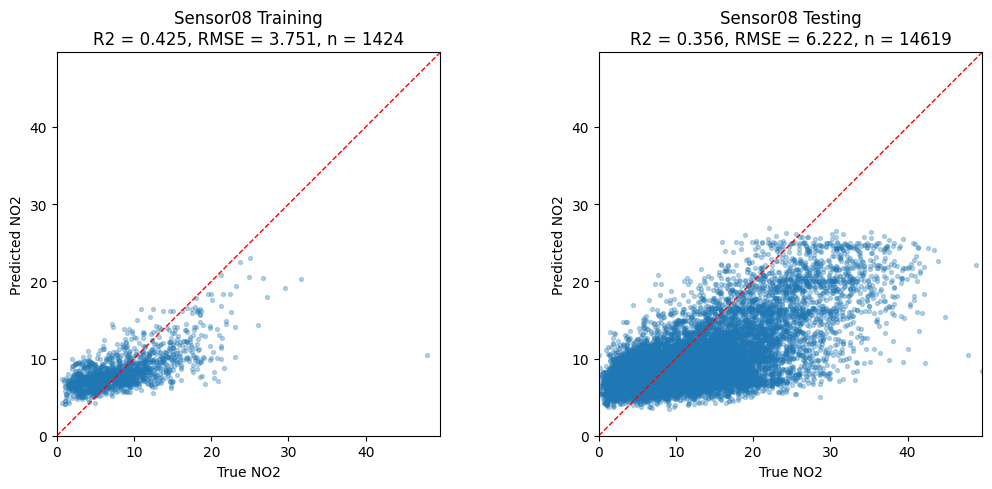

Training Sensor08 complete


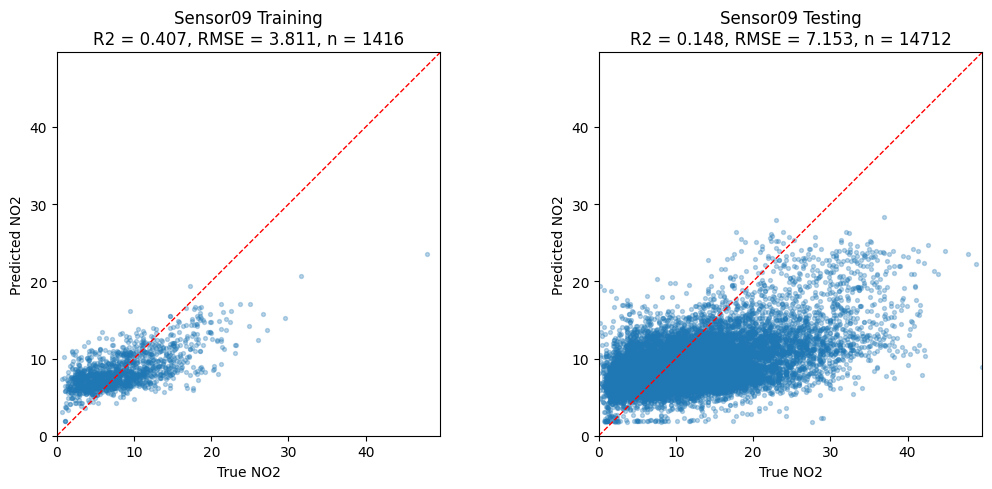

Training Sensor09 complete


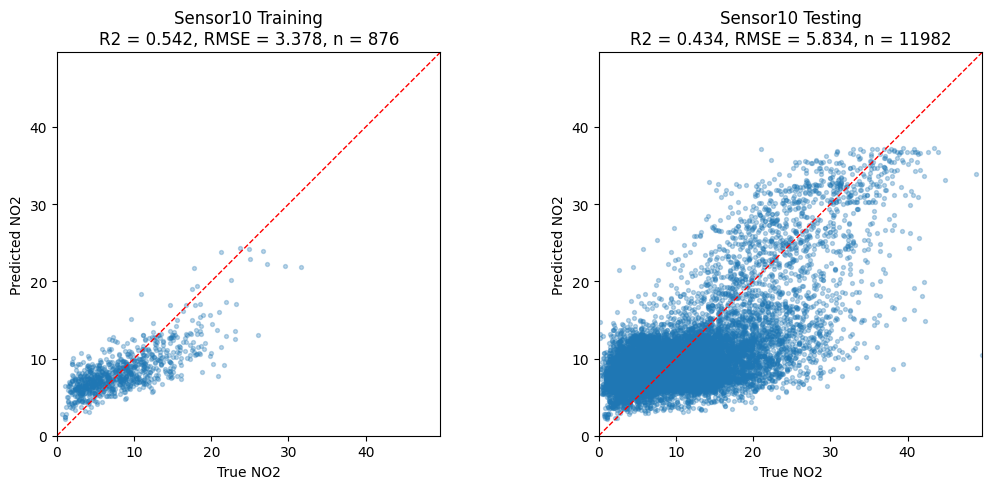

Training Sensor10 complete


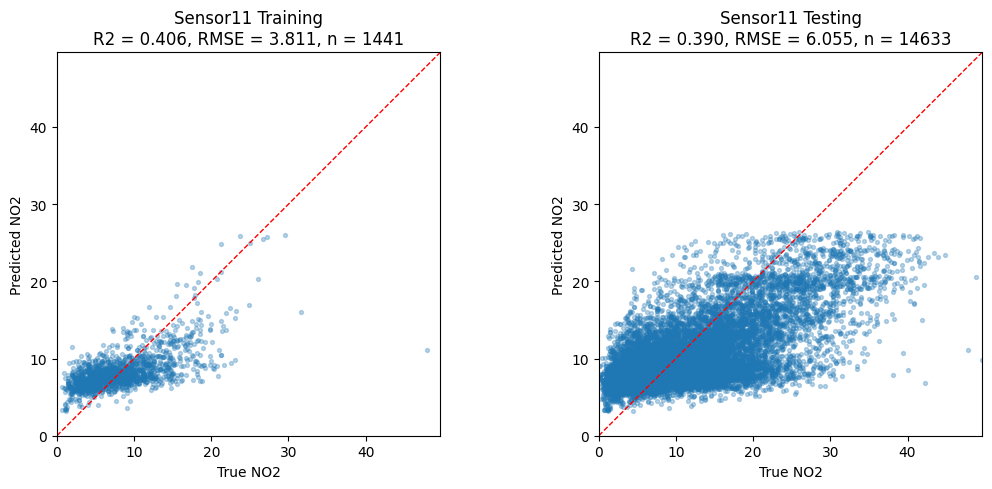

Training Sensor11 complete


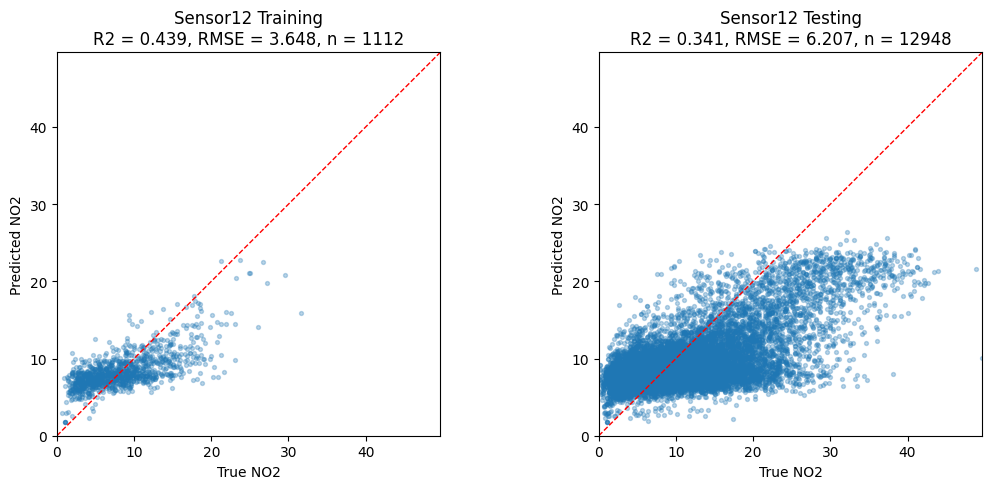

Training Sensor12 complete


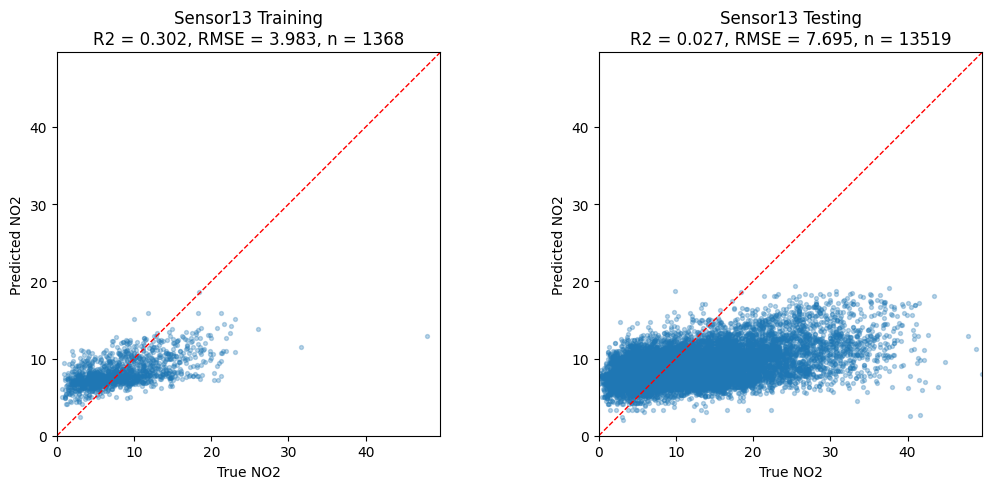

Training Sensor13 complete


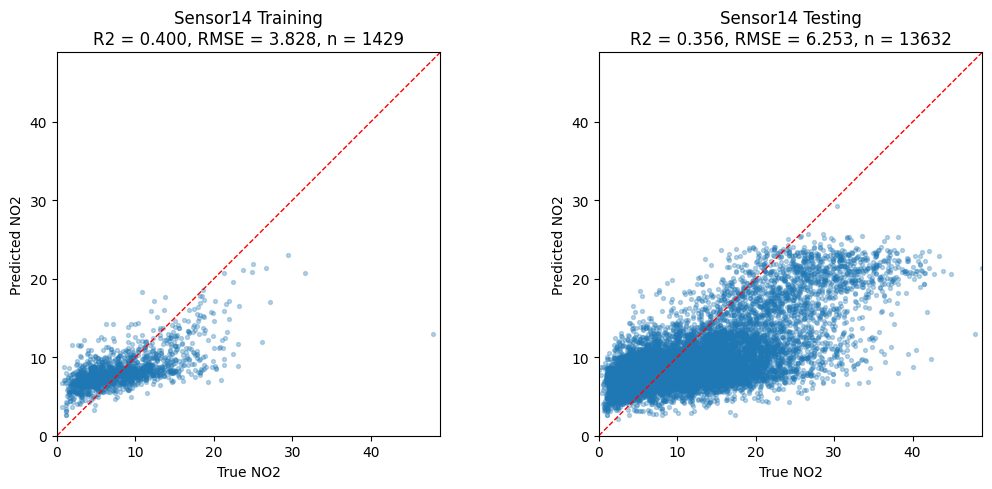

Training Sensor14 complete


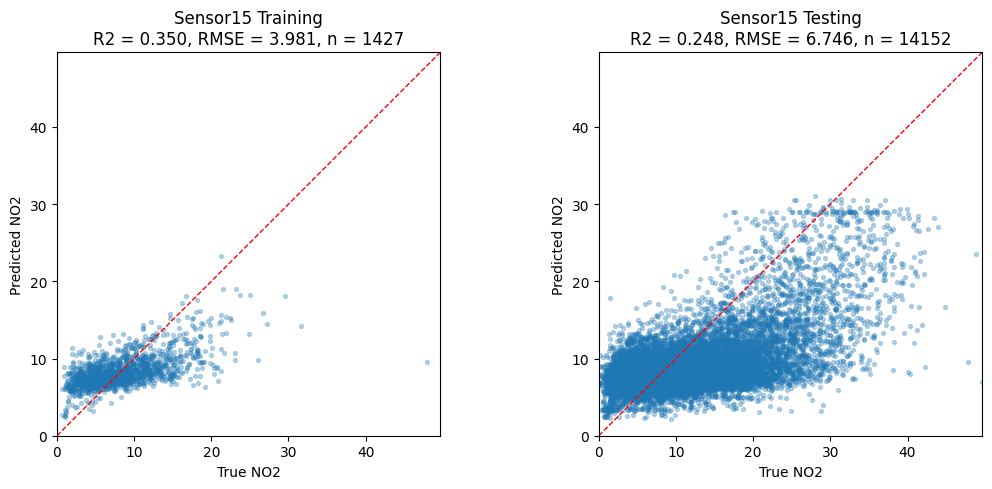

Training Sensor15 complete


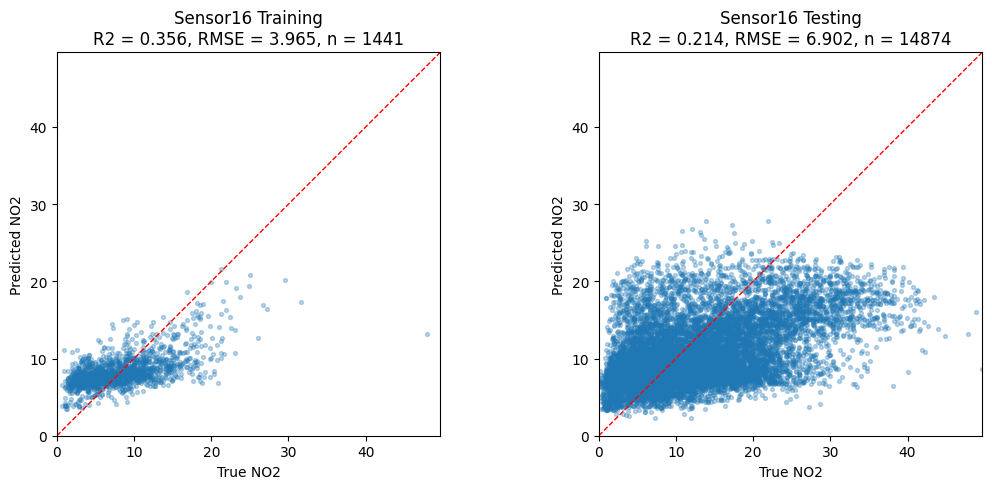

Training Sensor16 complete


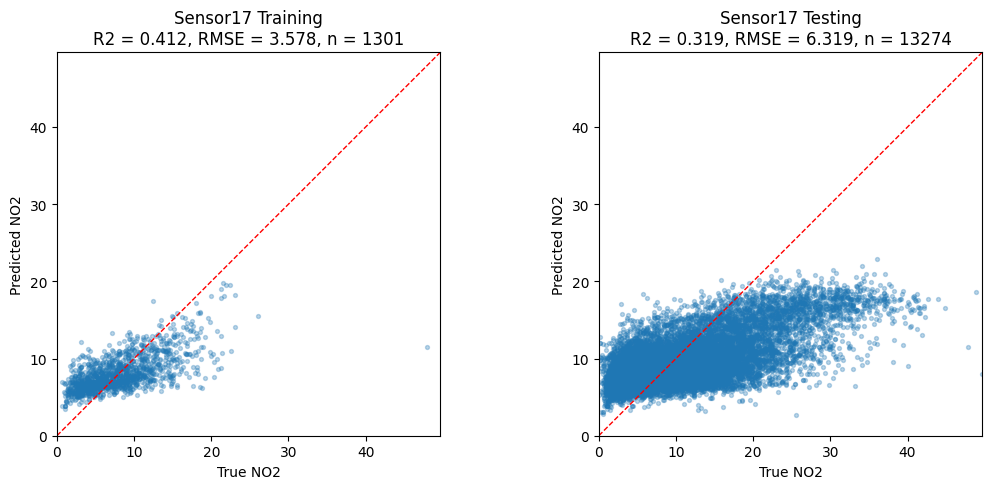

Training Sensor17 complete


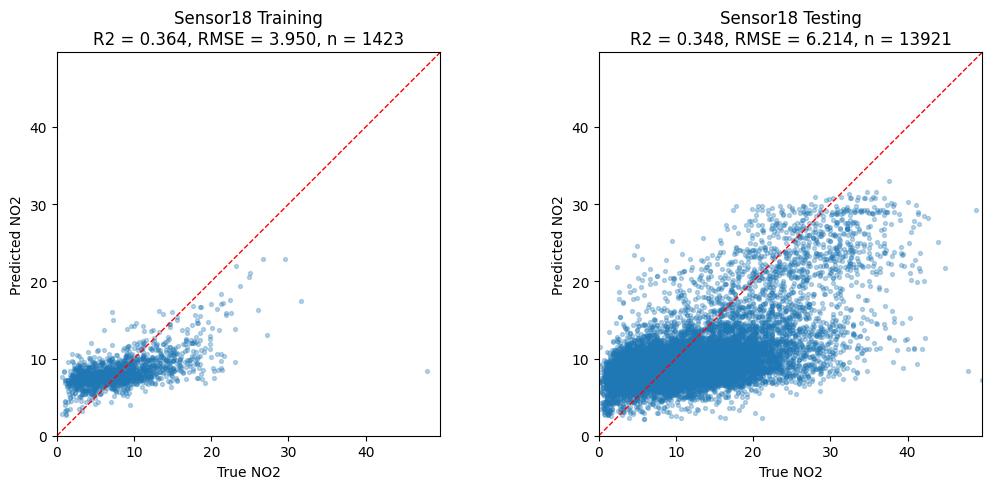

Training Sensor18 complete


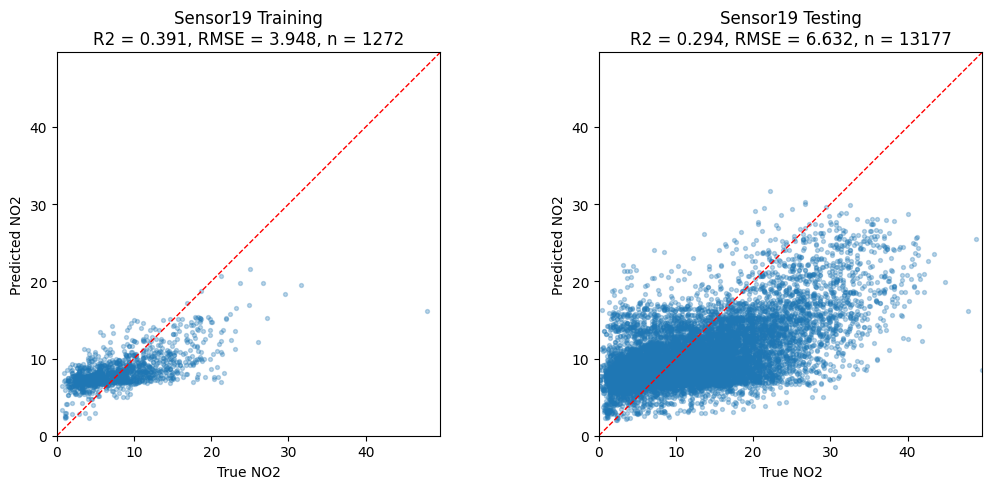

Training Sensor19 complete


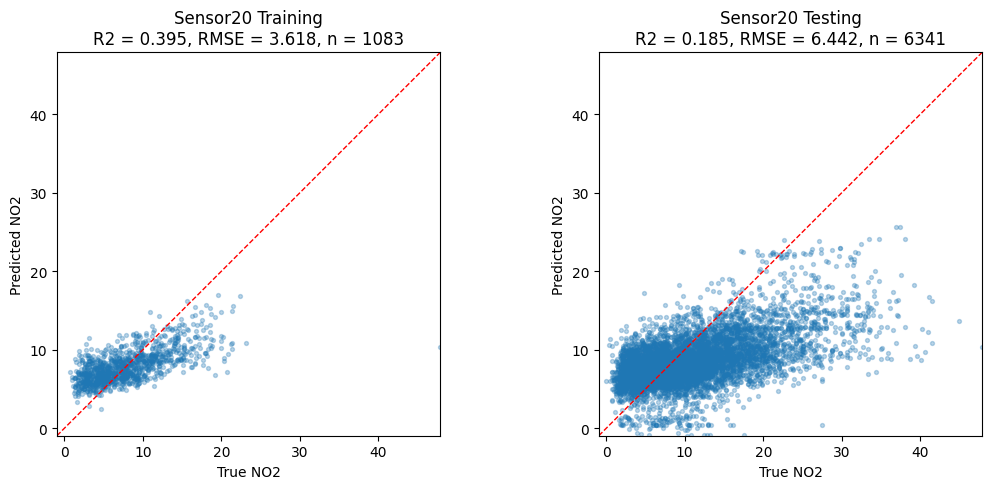

Training Sensor20 complete


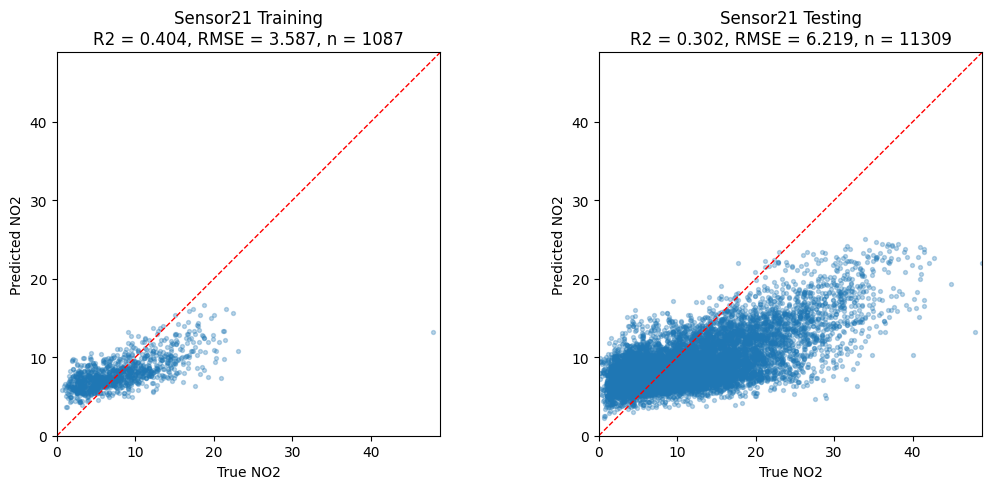

Training Sensor21 complete


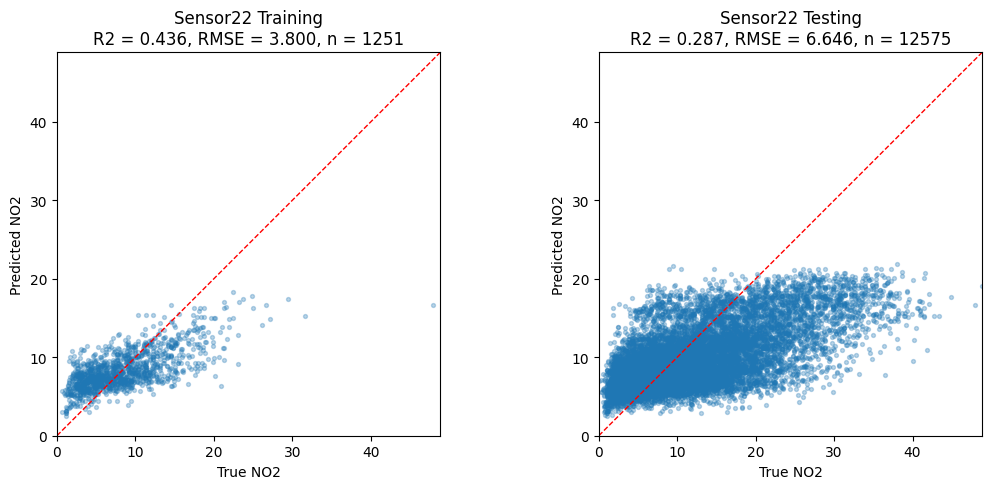

Training Sensor22 complete


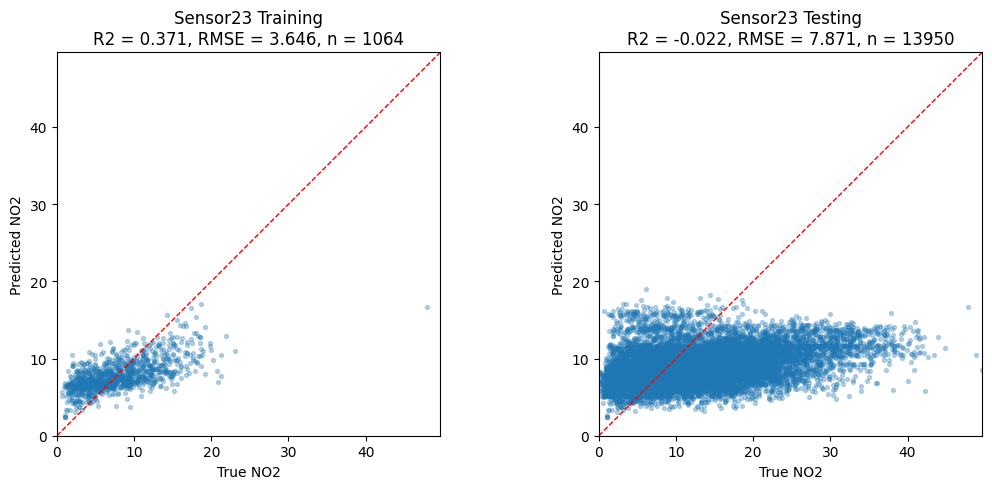

Training Sensor23 complete


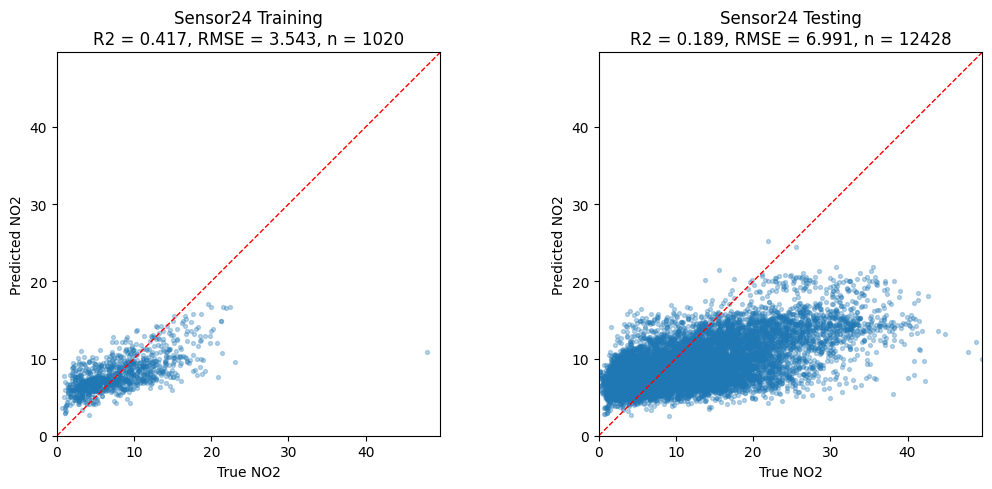

Training Sensor24 complete


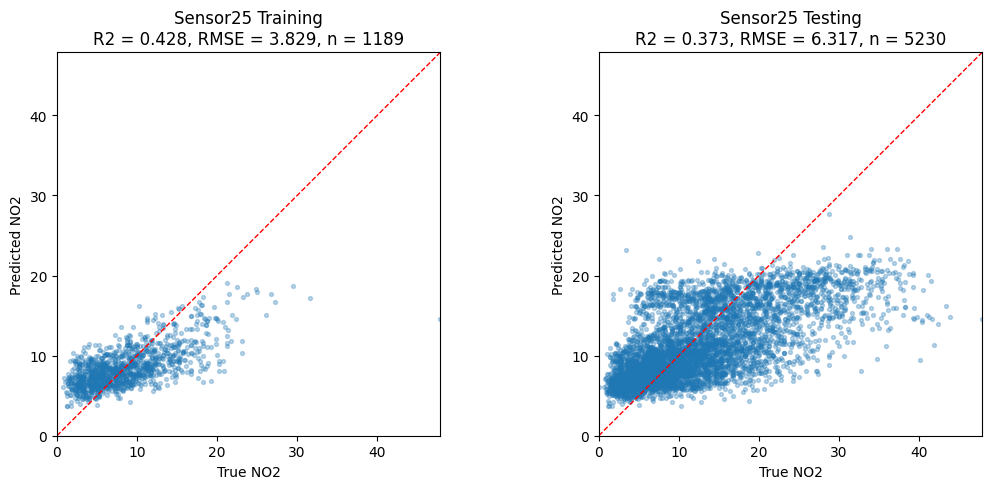

Training Sensor25 complete
    site  n_train  train_R2  train_RMSE  n_scored  test_R2  test_RMSE
Sensor01     1438     0.401       3.827     14560    0.295      6.526
Sensor02     1440     0.390       3.863     14842    0.377      6.140
Sensor03     1424     0.361       3.957     14662    0.324      6.375
Sensor04     1245     0.381       3.965     13816    0.269      6.726
Sensor05     1371     0.380       3.944     14338    0.333      6.407
Sensor06     1322     0.472       3.624     13006    0.433      5.935
Sensor07     1421     0.361       3.961     14282    0.233      6.755
Sensor08     1424     0.425       3.751     14619    0.356      6.222
Sensor09     1416     0.407       3.811     14712    0.148      7.153
Sensor10      876     0.542       3.378     11982    0.434      5.834
Sensor11     1441     0.406       3.811     14633    0.390      6.055
Sensor12     1112     0.439       3.648     12948    0.341      6.207
Sensor13     1368     0.302       3.983     13519    0.027     

In [64]:
data_folder = "training and testing data/no split training and testing data"
out_folder = "final data/no split final no2 dataset"
out_path = f"{out_folder}/predicted_no2_bysite.csv"

features = ["no2_wrk_aux", "no_wrk_aux", "o3_wrk_aux", "rh", "temp"]
target = "no2"
full_index = pd.date_range("2023-01-01 00:00:00", "2024-12-31 23:00:00", freq="h")

pred_dict = {}
results = []
importance_rows = []

for i in range(1, 26):
    xx = f"{i:02d}"

    train_path = f"{data_folder}/Sensor{xx}_training.csv"
    test_path = f"{data_folder}/Sensor{xx}_testing.csv"

    train = pd.read_csv(train_path, parse_dates=["datetime_utc"])
    test = pd.read_csv(test_path, parse_dates=["datetime_utc"])

    if len(train) == 0:
        print(f"Sensor{xx}: no training rows, skipping")
        continue

    model = XGBRegressor(
        n_estimators=150,
        max_depth=2,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=0.8,
        random_state=42,
    )

    model.fit(train[features], train[target])

    importances = pd.Series(model.feature_importances_, index=features)

    top2 = importances.sort_values(ascending=False).head(2)
    importance_rows.append({
        "site": f"Sensor{xx}",
        "top1_feature": top2.index[0],
        "top1_importance": round(top2.iloc[0], 3),
        "top2_feature": top2.index[1],
        "top2_importance": round(top2.iloc[1], 3),
    })

    train_pred = model.predict(train[features])
    train_r2 = r2_score(train[target], train_pred)
    train_rmse = np.sqrt(mean_squared_error(train[target], train_pred))
    test["predicted_no2"] = np.nan
    
    has_inputs = test[features].notna().all(axis=1)
    test.loc[has_inputs, "predicted_no2"] = model.predict(test.loc[has_inputs, features])

    scored = test.dropna(subset=[target, "predicted_no2"])

    r2 = r2_score(scored[target], scored["predicted_no2"])

    rmse = np.sqrt(mean_squared_error(scored[target], scored["predicted_no2"]))

    results.append({
        "site": f"Sensor{xx}",
        "n_train": len(train),
        "train_R2": round(train_r2, 3),
        "train_RMSE": round(train_rmse, 3),
        "n_scored": len(scored),
        "test_R2": round(r2, 3),
        "test_RMSE": round(rmse, 3),
    })

    all_vals = pd.concat([train[target], pd.Series(train_pred),
                          scored[target], scored["predicted_no2"]])
    lo = all_vals.min()
    hi = all_vals.max()

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    panels = [
        (axes[0], train[target], train_pred, "Training", train_r2, train_rmse),
        (axes[1], scored[target], scored["predicted_no2"], "Testing", r2, rmse),
    ]

    for ax, true_vals, pred_vals, name, r2_val, rmse_val in panels:

        ax.scatter(true_vals, pred_vals, s=8, alpha=0.3)

        ax.plot([lo, hi], [lo, hi], color="red", linestyle="--", linewidth=1)

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal")

        ax.set_title(f"Sensor{xx} {name}\nR2 = {r2_val:.3f}, "
                     f"RMSE = {rmse_val:.3f}, n = {len(true_vals)}")
        ax.set_xlabel("True NO2")
        ax.set_ylabel("Predicted NO2")

    plt.tight_layout()
    plt.show()

    pred_dict[f"Sensor{xx}"] = (
        test.set_index("datetime_utc")["predicted_no2"].reindex(full_index)
    )

    print(f"Training Sensor{xx} complete")

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\nMean Train R2:", round(results_df["train_R2"].mean(), 3))
print("\nMean Test R2:", round(results_df["test_R2"].mean(), 3))
print("\nMean Train RMSE:", round(results_df["train_RMSE"].mean(), 3))
print("\nMean Test RMSE:", round(results_df["test_RMSE"].mean(), 3))

importance_df = pd.DataFrame(importance_rows)
print("\nTop two feature importances by site:")
print(importance_df.to_string(index=False))

print("\nHow often each feature is the #1 feature:")
print(importance_df["top1_feature"].value_counts().to_string())

pred_wide = pd.DataFrame(pred_dict)
pred_wide.index.name = "datetime_utc"
pred_out = pred_wide.reset_index()

pred_out.insert(1, "datetime_est", pred_out["datetime_utc"] - pd.Timedelta(hours=5))
pred_out.insert(2, "datetime_edt", pred_out["datetime_utc"] - pd.Timedelta(hours=4))

pred_out[pred_wide.columns] = pred_out[pred_wide.columns].round(1)
pred_out.to_csv(out_path, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("\nSaved:", out_path, pred_out.shape)

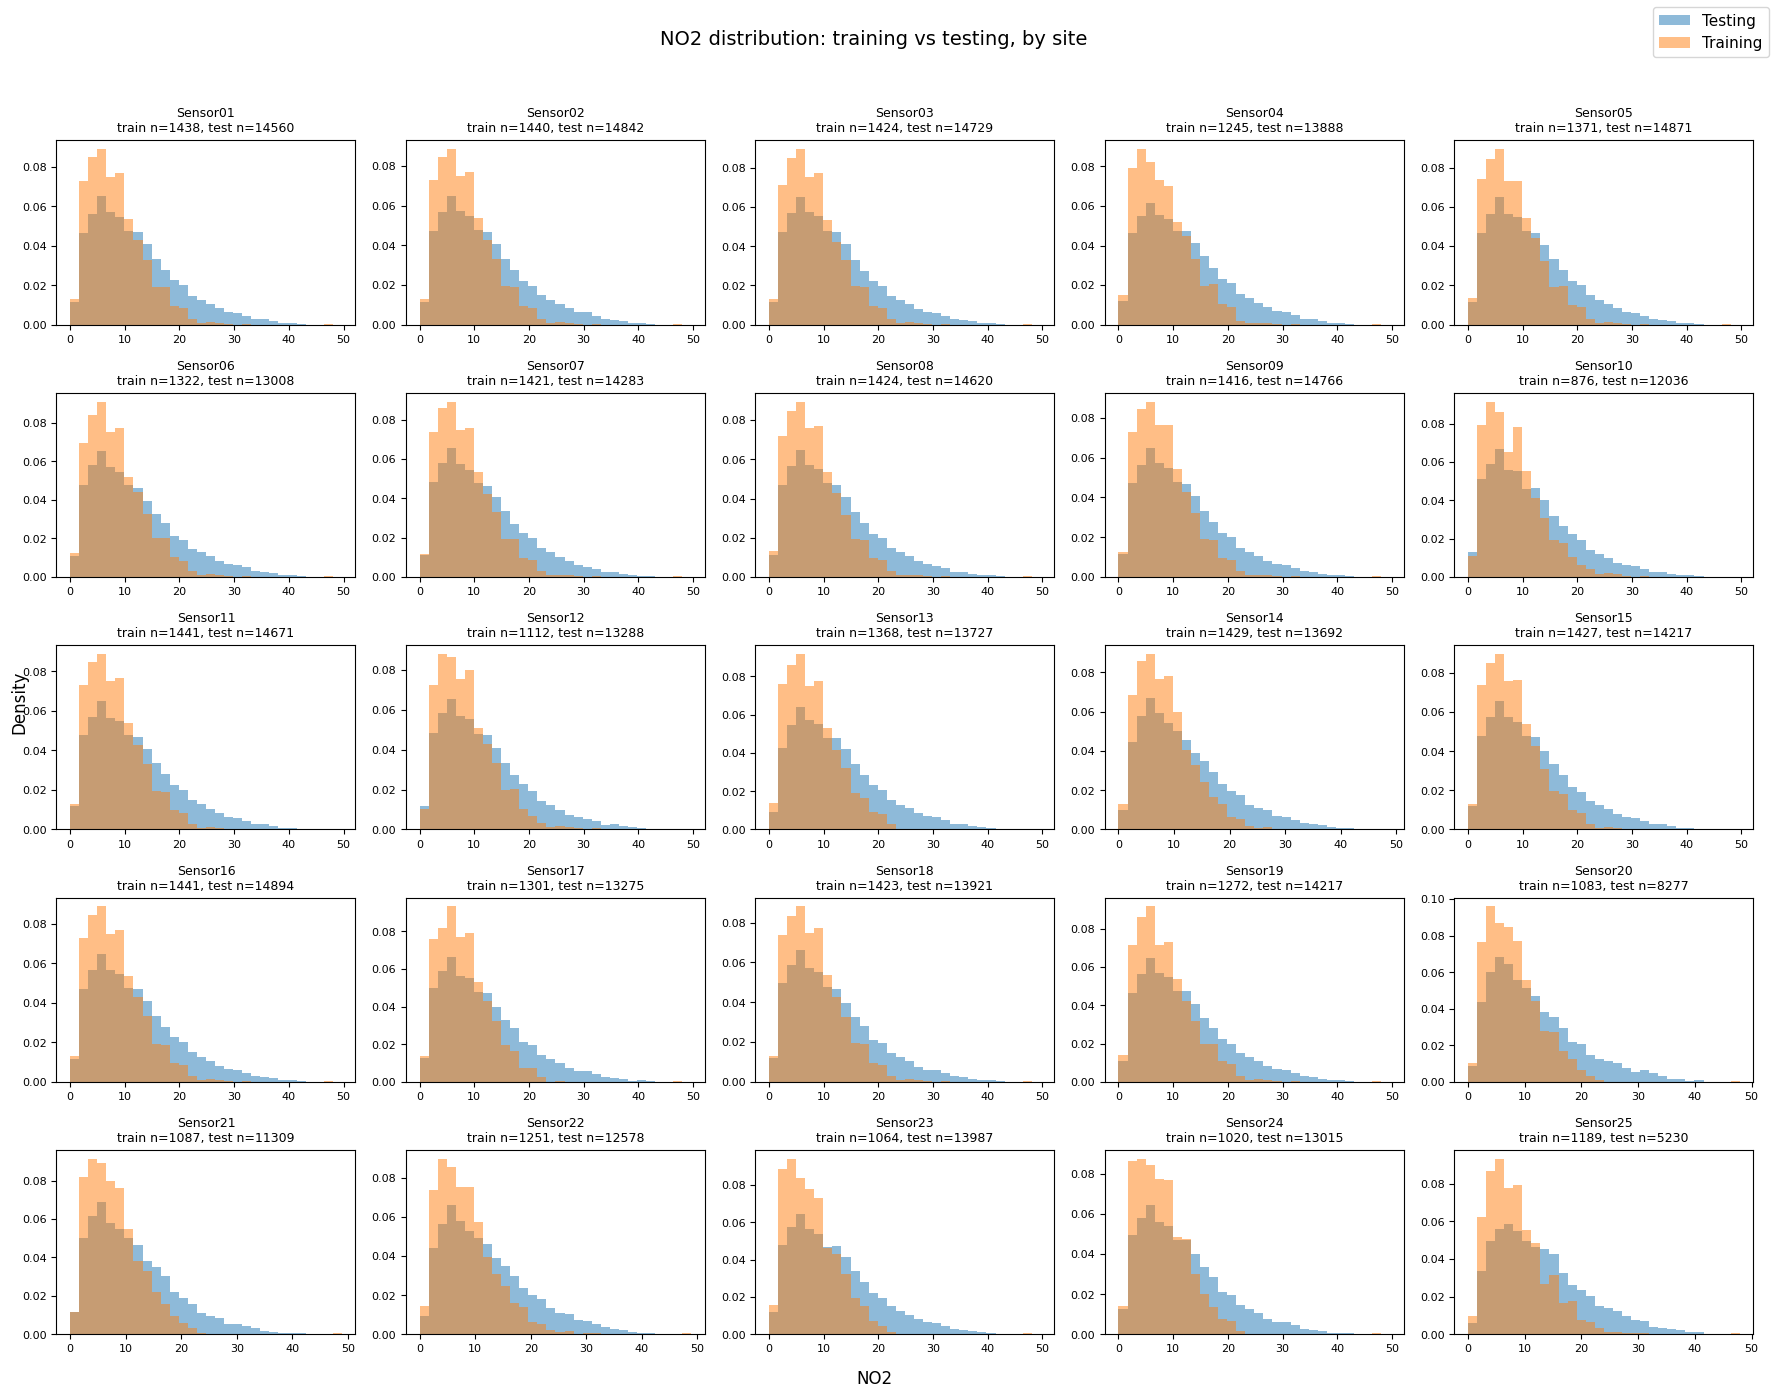

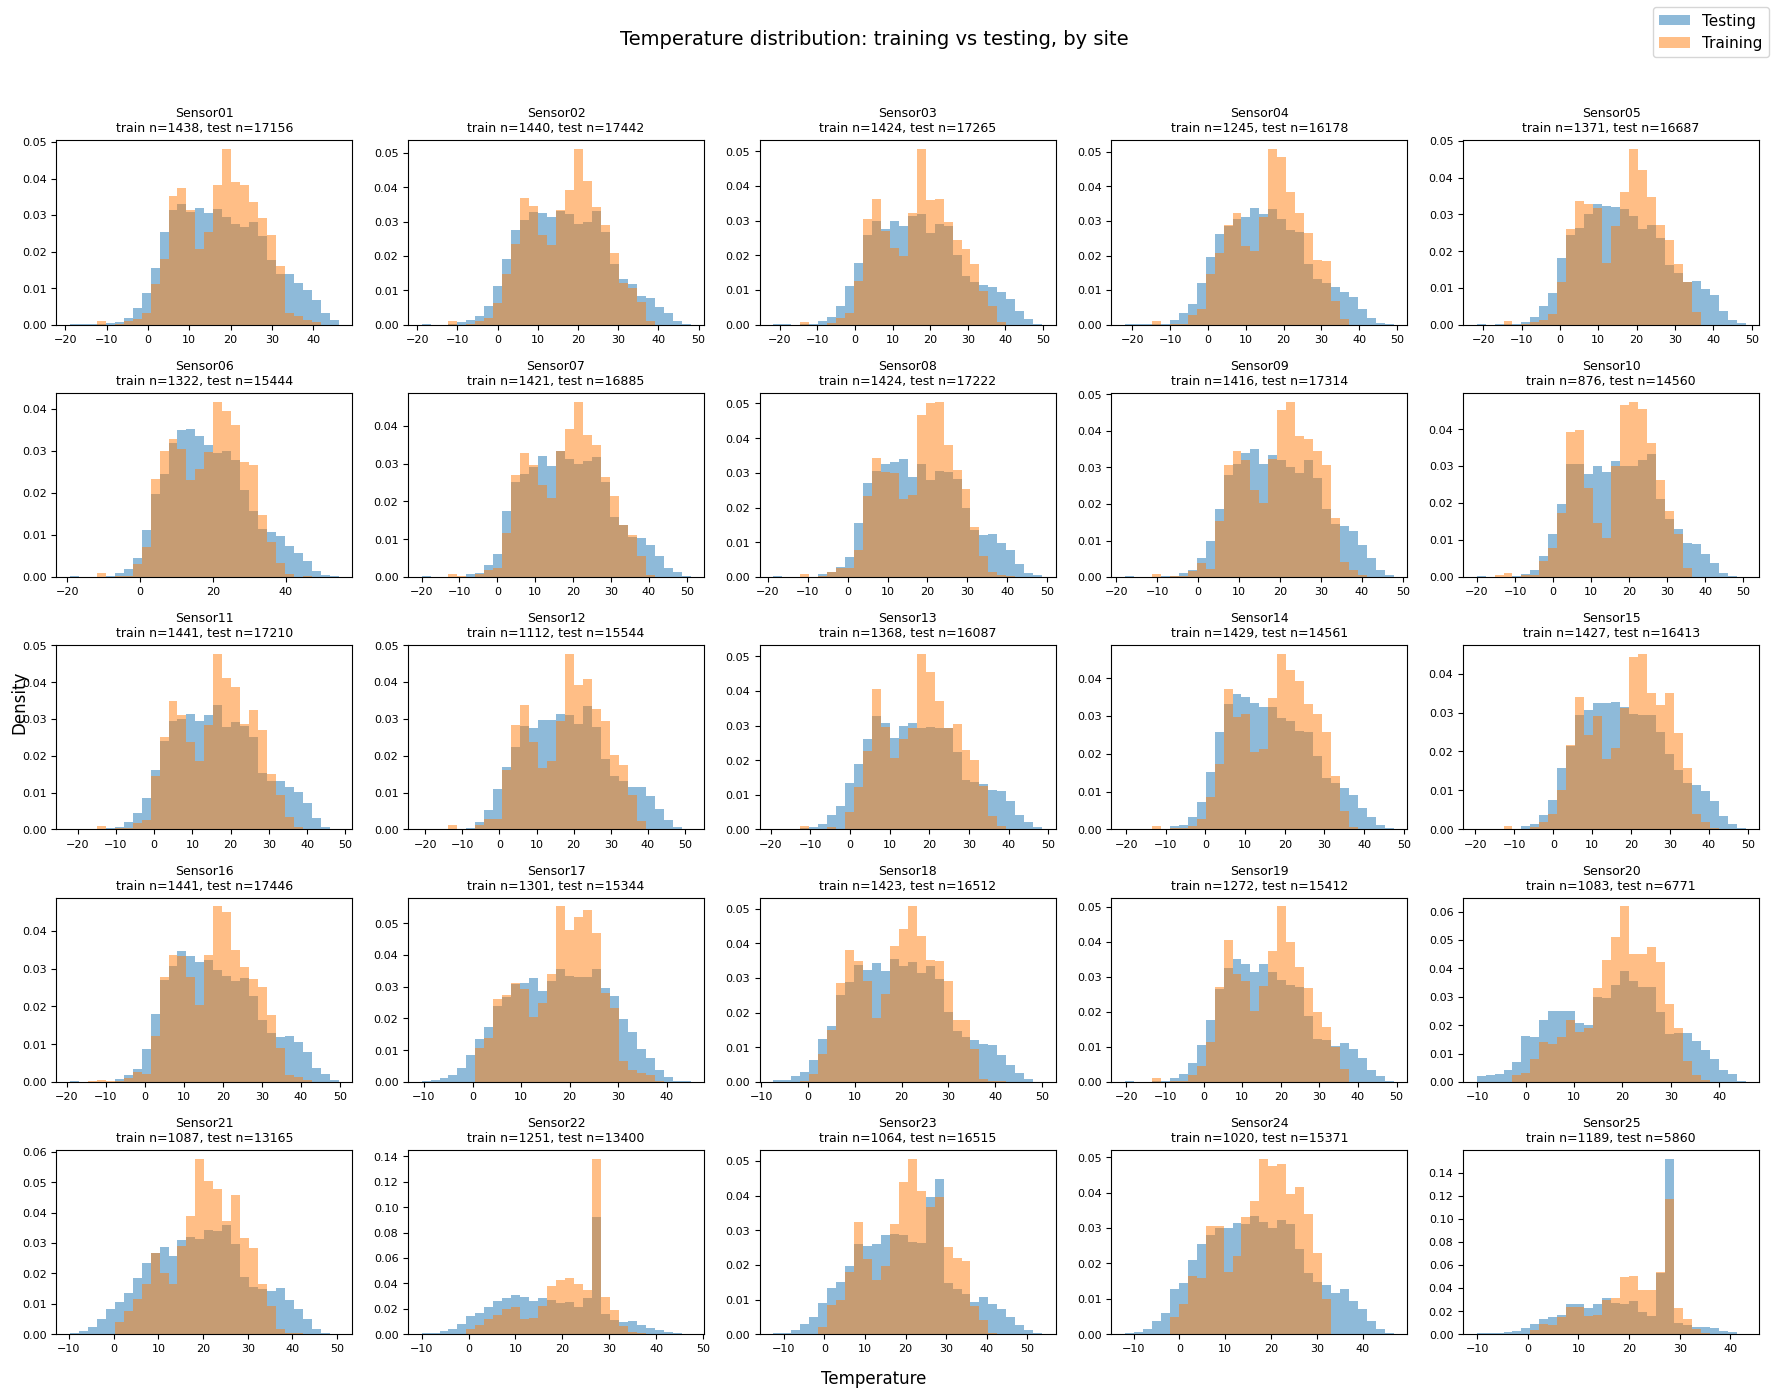

In [65]:
data_folder = "training and testing data/no split training and testing data"

variables = [("no2", "NO2"), ("temp", "Temperature")]

train_data = {}
test_data = {}

for i in range(1, 26):
    xx = f"{i:02d}"

    train_path = f"{data_folder}/Sensor{xx}_training.csv"
    test_path = f"{data_folder}/Sensor{xx}_testing.csv"

    train_data[f"Sensor{xx}"] = pd.read_csv(train_path)
    test_data[f"Sensor{xx}"] = pd.read_csv(test_path)

for col, label in variables:

    fig, axes = plt.subplots(5, 5, figsize=(18, 14))

    axes = axes.flatten()

    for pos, name in enumerate(train_data.keys()):
        ax = axes[pos]

        tr = train_data[name][col].dropna()
        te = test_data[name][col].dropna()

        if len(tr) == 0 or len(te) == 0:
            ax.set_title(f"{name} (no data)")
            continue

        lo = min(tr.min(), te.min())
        hi = max(tr.max(), te.max())
        bins = np.linspace(lo, hi, 31)

        ax.hist(te, bins=bins, density=True, alpha=0.5,
                color="tab:blue", label="Testing")

        ax.hist(tr, bins=bins, density=True, alpha=0.5,
                color="tab:orange", label="Training")

        ax.set_title(f"{name}\ntrain n={len(tr)}, test n={len(te)}", fontsize=9)

        ax.tick_params(labelsize=8)

    for ax in axes[len(train_data):]:
        ax.axis("off")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", fontsize=11)

    fig.suptitle(f"{label} distribution: training vs testing, by site", fontsize=14)
    fig.supxlabel(label)
    fig.supylabel("Density")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

### IV a. Identify split low RSD data

In [66]:
co2_path = "cleaned data/cleaned co2/cleaned_co2_bysite.csv"
ref_path = "cleaned data/cleaned near road reference data/nr cleaned no2 23 24.csv"
out_folder = "low RSD time periods/split low RSD time periods"
out_path = f"{out_folder}/split_low_rsd_hours.csv"

no2_split = 20
min_sites = 18
keep_fraction = 0.10

os.makedirs(out_folder, exist_ok=True)
co2 = pd.read_csv(co2_path, parse_dates=["datetime_utc"])
ref = pd.read_csv(ref_path, parse_dates=["datetime_utc"])

site_cols = [c for c in co2.columns if c.startswith("Sensor")]

co2 = co2.set_index("datetime_utc")

ref_no2 = ref.set_index("datetime_utc")["no2"].reindex(co2.index)
n_online = co2[site_cols].notna().sum(axis=1)

rsd = co2[site_cols].std(axis=1) / co2[site_cols].mean(axis=1) * 100
rsd = rsd.where(n_online >= min_sites)

high_mask = ref_no2 > no2_split
low_mask = ref_no2 <= no2_split

co2_high = co2[high_mask]
co2_low = co2[low_mask]

regimes = {
    f"above_{no2_split}ppb": rsd[high_mask],
    f"at_or_below_{no2_split}ppb": rsd[low_mask],
}


selected_parts = []

for label, regime_rsd in regimes.items():

    valid = regime_rsd.dropna()
    cutoff = valid.quantile(keep_fraction)

    chosen = valid[valid <= cutoff]

    part = chosen.to_frame(name="rsd_percent").reset_index()
    part["regime"] = label

    selected_parts.append(part)

    print(f"{label}: {len(co2_high) if 'above' in label else len(co2_low)} hours, "
          f"{len(valid)} with valid RSD, RSD cutoff = {cutoff:.3f}%, "
          f"{len(part)} hours selected")

split_df = pd.concat(selected_parts).sort_values("datetime_utc")
split_df["rsd_percent"] = split_df["rsd_percent"].round(3)
split_df = split_df[["datetime_utc", "rsd_percent", "regime"]]

split_df.to_csv(out_path, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("\nTotal hours saved:", len(split_df))
print(split_df["regime"].value_counts().to_string())
print(split_df.head())

above_20ppb: 2242 hours, 1969 with valid RSD, RSD cutoff = 1.962%, 197 hours selected
at_or_below_20ppb: 12698 hours, 11920 with valid RSD, RSD cutoff = 1.281%, 1192 hours selected

Total hours saved: 1389
regime
at_or_below_20ppb    1192
above_20ppb           197
         datetime_utc  rsd_percent             regime
0 2023-02-02 16:00:00        0.848  at_or_below_20ppb
1 2023-02-02 17:00:00        1.071  at_or_below_20ppb
2 2023-02-02 18:00:00        1.036  at_or_below_20ppb
0 2023-02-03 01:00:00        1.342        above_20ppb
1 2023-02-03 03:00:00        1.712        above_20ppb
